# 02. IPCA — Análise da Inflação Brasileira

## IPCA Geral • IBGE/SIDRA • PostgreSQL

Este notebook analisa a evolução do IPCA geral após a validação dos dados realizada em: ```00.auditoria_dados.ipynb```

O fluxo operacional esperado é:

```text
      IBGE/SIDRA
          |
          v
       pipeline
          |
          v
      PostgreSQL
          |
          v
  00.auditoria_dados
          |
          v
      02.ipca
```

Este notebook assume que:

- o pipeline do IPCA já foi executado;
- a tabela `bcb.ipca_geral` está atualizada;
- a auditoria dos dados foi concluída;
- os dados estão aptos para análise.

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.

---



#### Objetivos

1. Entender as principais medidas do IPCA geral.
2. Examinar a cobertura histórica da série.
3. Analisar a inflação mensal.
4. Analisar a inflação acumulada em 12 meses.
5. Identificar períodos de aceleração e desaceleração.
6. Examinar a dinâmica de curto e médio prazo.
7. Explorar observações extremas e diferentes regimes históricos.
8. Preparar uma representação analítica mensal para análises posteriores.

### 1. O que é o IPCA?

- O IPCA é uma das principais medidas da inflação ao consumidor no Brasil.
- A inflação representa a variação do nível de preços ao longo do tempo.
- Neste projeto, o IPCA será analisado inicialmente em nível agregado.

Posteriormente, a análise será decomposta em:

```text
IPCA geral
     |
     +-- grupos
     |
     +-- subgrupos
     |
     +-- itens
     |
     +-- subitens
```

Essa separação será importante porque o índice agregado informa quanto
os preços variaram, enquanto seus componentes ajudam a entender de onde
veio essa variação.

### 2. Medidas utilizadas

A tabela `bcb.ipca_geral` contém diferentes representações da inflação.



#### 2.1 Variação mensal

- ```indice``` $\to\qquad$ Representa a variação percentual do IPCA no mês.

Exemplo conceitual:

```text
janeiro   -> 0,40%
fevereiro -> 0,65%
março     -> 0,30%
```

Essa será uma das principais variáveis para análises econômicas e para
futura modelagem.

#### 2.2 Acumulado no ano

- ```acumulado``` $\to\qquad$ Representa a inflação acumulada desde o início do ano até o mês corrente.

Portanto, a interpretação dessa variável depende da posição do mês
dentro do ano.

#### 2.3 Acumulado em 12 meses

- ```acumulado12m``` $\to\qquad$ 
Representa a inflação acumulada nos últimos 12 meses.

Essa medida oferece uma visão mais persistente da dinâmica inflacionária
do que a variação de um único mês.

#### 2.4 Número-índice

- ```nindice``` $\to\qquad$ O número-índice representa o nível acumulado do índice de preços em relação à base metodológica da série.

Diferentemente da variação mensal, o número-índice representa um nível,
e não uma taxa de variação mensal.

### 3. Configuração do ambiente

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 4. Importações

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

### 5. Carregar IPCA geral do PostgreSQL

O notebook apenas consome a tabela já atualizada pelo pipeline.

In [3]:
ipca = pd.read_sql(
    """
    SELECT
        date,
        indice,
        nindice,
        acumulado,
        acumulado12m
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

#### 5.1 Padronizar datas

Antes de qualquer operação temporal, garantimos explicitamente que a
coluna `date` esteja em formato datetime e que a base esteja ordenada.

In [4]:
ipca["date"] = pd.to_datetime(
    ipca["date"]
)

ipca = (
    ipca
    .sort_values("date")
    .reset_index(drop=True)
)

ipca.tail()

,date,indice,nindice,acumulado,acumulado12m
556,2026-04-01,0.6700,7596.0900,2.6000,4.3900
557,2026-05-01,0.5800,7640.1500,3.2000,4.7200
558,2026-06-01,0.1600,7652.3700,3.3600,4.6400
559,2026-07-01,0.0700,7657.7300,3.4400,4.4400
560,2026-08-01,-0.3200,7633.2300,3.1100,4.2200


### 6. Cobertura histórica

In [5]:
resumo_serie = pd.DataFrame(
    [
        {
            "serie": "IPCA Geral",
            "inicio": ipca["date"].min(),
            "fim": ipca["date"].max(),
            "observacoes": len(ipca),
        }
    ]
)

resumo_serie

,serie,inicio,fim,observacoes
0,IPCA Geral,1979-12-01,2026-08-01,561


### 7. Observações mais recentes

In [6]:
ipca.tail(12)

,date,indice,nindice,acumulado,acumulado12m
549,2025-09-01,0.4800,7359.0600,3.6400,5.1700
550,2025-10-01,0.0900,7365.6800,3.7300,4.6800
551,2025-11-01,0.1800,7378.9400,3.9200,4.4600
552,2025-12-01,0.3300,7403.2900,4.2600,4.2600
553,2026-01-01,0.3300,7427.7200,0.3300,4.4400
554,2026-02-01,0.7000,7479.7100,1.0300,3.8100
555,2026-03-01,0.8800,7545.5300,1.9200,4.1400
556,2026-04-01,0.6700,7596.0900,2.6000,4.3900
557,2026-05-01,0.5800,7640.1500,3.2000,4.7200
558,2026-06-01,0.1600,7652.3700,3.3600,4.6400


### 8. Estatísticas descritivas

Como a série atravessa diferentes regimes inflacionários, estatísticas
calculadas sobre todo o histórico devem ser interpretadas com cautela.

In [7]:
ipca[
    [
        "indice",
        "nindice",
        "acumulado",
        "acumulado12m",
    ]
].describe()

,indice,nindice,acumulado,acumulado12m
count,560.0000,561.0000,560.0000,549.0000
mean,5.5008,2483.7638,88.9647,291.2646
std,10.5256,2289.7936,256.3168,840.6683
min,-0.6800,0.0000,-0.1600,1.6500
25%,0.3600,0.1478,2.4200,4.9400
50%,0.7000,2165.2900,4.7150,7.3900
75%,6.3700,4059.8600,40.1625,115.0300
max,82.3900,7657.7300,2477.1500,6821.3100


---

## PARTE I — INFLAÇÃO MENSAL



### 9. Evolução histórica da variação mensal

A coluna `indice` representa a inflação observada em cada mês.

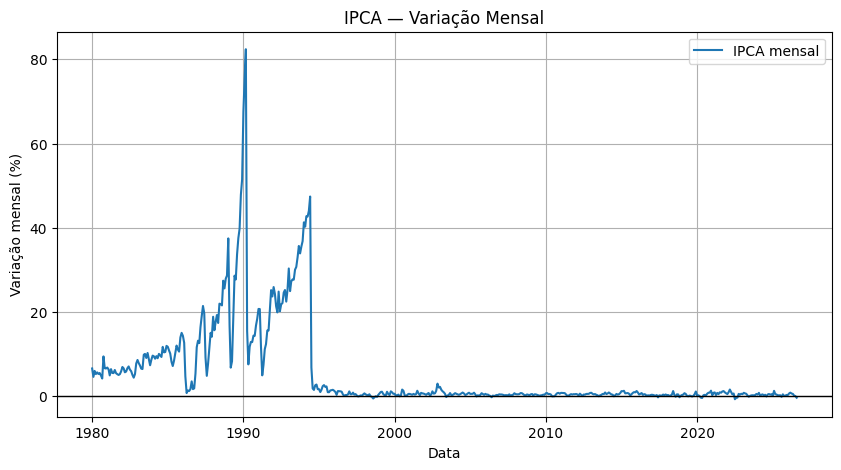

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(
    ipca["date"],
    ipca["indice"],
    label="IPCA mensal",
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title("IPCA — Variação Mensal")
plt.xlabel("Data")
plt.ylabel("Variação mensal (%)")
plt.grid(True)
plt.legend()

plt.show()

### 10. Diferentes regimes históricos

O gráfico completo pode ser dominado visualmente por períodos históricos
com inflação muito elevada.

Isso significa que oscilações recentes relativamente pequenas podem ficar
visualmente comprimidas.

Portanto, além do histórico completo, analisaremos separadamente períodos
mais recentes.

#### 10.1 IPCA desde 1995

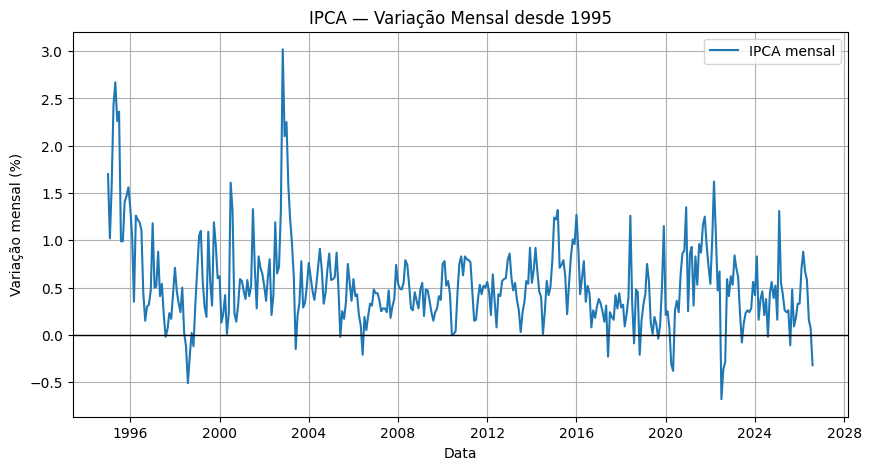

In [9]:
ipca_pos_1995 = ipca[ipca["date"] >= "1995-01-01"].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    ipca_pos_1995["date"],
    ipca_pos_1995["indice"],
    label="IPCA mensal",
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title("IPCA — Variação Mensal desde 1995")
plt.xlabel("Data")
plt.ylabel("Variação mensal (%)")
plt.grid(True)
plt.legend()

plt.show()

#### 10.2 Últimos 10 anos

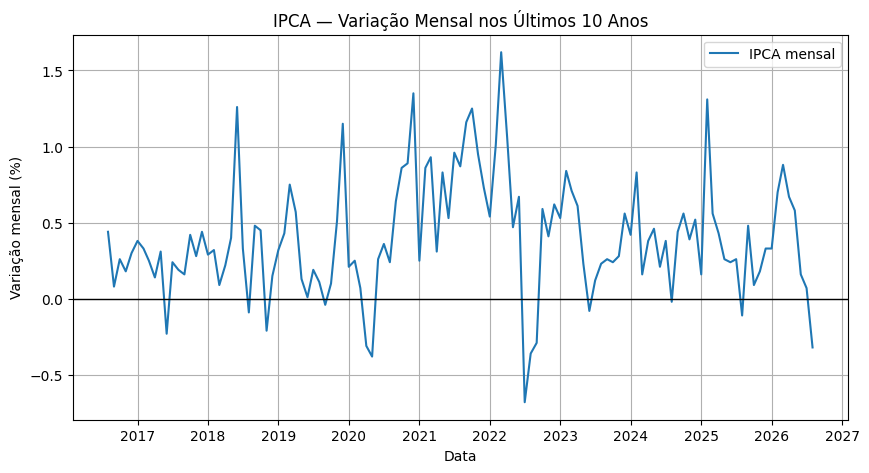

In [10]:
data_inicio_10a = (
    ipca["date"].max()
    - pd.DateOffset(years=10)
)

ipca_10a = ipca[
    ipca["date"] >= data_inicio_10a
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    ipca_10a["date"],
    ipca_10a["indice"],
    label="IPCA mensal",
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title("IPCA — Variação Mensal nos Últimos 10 Anos")
plt.xlabel("Data")
plt.ylabel("Variação mensal (%)")
plt.grid(True)
plt.legend()

plt.show()

### 11. Distribuição histórica da inflação mensal

O histograma mostra quantas vezes determinadas faixas de inflação mensal
apareceram ao longo do histórico.

Assim como ocorreu com a SELIC, essa distribuição combina diferentes
regimes econômicos e não deve ser interpretada como uma distribuição
única e estável no tempo.

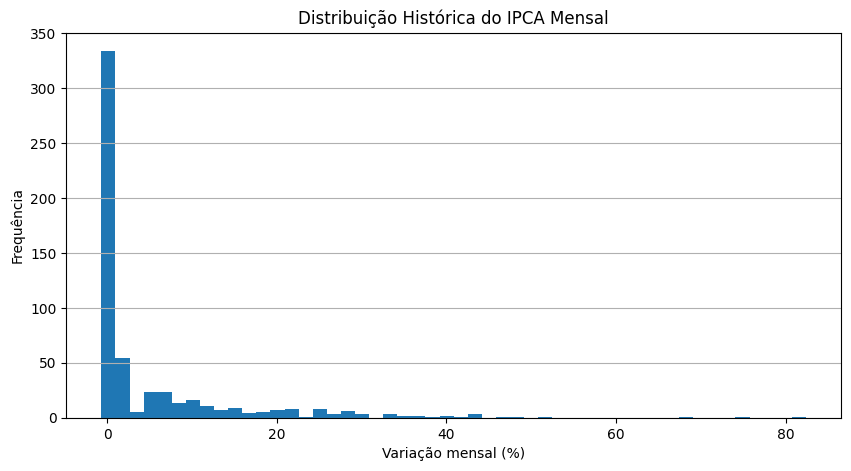

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(
    ipca["indice"].dropna(),
    bins=50,
)

plt.title("Distribuição Histórica do IPCA Mensal")
plt.xlabel("Variação mensal (%)")
plt.ylabel("Frequência")
plt.grid(True, axis="y")

plt.show()

### 12. Observações mensais extremas

Os maiores e menores valores históricos são úteis para:

- identificar diferentes regimes de inflação;
- contextualizar outliers;
- evitar tratar automaticamente valores extremos como erro;
- compreender futuras dificuldades de modelagem.

#### Maiores variações mensais

In [12]:
ipca.nlargest(10, "indice",)[
    ["date", "indice", "acumulado12m"]
]

,date,indice,acumulado12m
123,1990-03-01,82.3900,6390.5300
122,1990-02-01,75.7300,3701.2900
121,1990-01-01,67.5500,2426.1200
120,1989-12-01,51.5000,1972.9100
119,1989-11-01,47.8200,1660.9500
174,1994-06-01,47.4300,4922.6000
173,1994-05-01,44.0300,4331.1900
171,1994-03-01,42.7500,3417.3900
172,1994-04-01,42.6800,3828.4900
169,1994-01-01,41.3100,2693.8400


#### Menores variações mensais

In [13]:
ipca.nsmallest(10, "indice",)[
    ["date", "indice", "acumulado12m"]
]

,date,indice,acumulado12m
511,2022-07-01,-0.6800,10.0700
224,1998-08-01,-0.5100,2.5500
485,2020-05-01,-0.3800,1.8800
512,2022-08-01,-0.3600,8.7300
560,2026-08-01,-0.3200,4.2200
484,2020-04-01,-0.3100,2.4000
513,2022-09-01,-0.2900,7.1700
450,2017-06-01,-0.2300,3.0000
225,1998-09-01,-0.2200,2.2700
318,2006-06-01,-0.2100,4.0300


---

## PARTE II — INFLAÇÃO EM 12 MESES



### 13. Evolução histórica

A inflação acumulada em 12 meses apresenta uma visão mais persistente
do processo inflacionário que a variação mensal isolada.

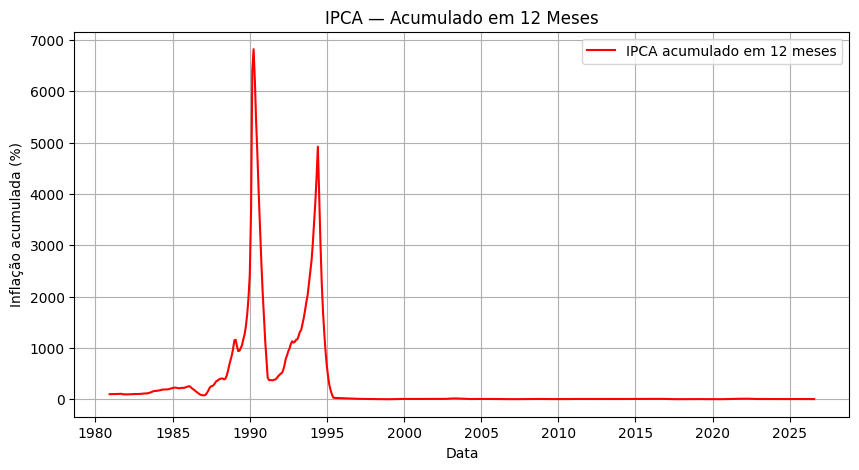

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    ipca["date"],
    ipca["acumulado12m"],
    color="red",
    label="IPCA acumulado em 12 meses",
)

plt.title("IPCA — Acumulado em 12 Meses")
plt.xlabel("Data")
plt.ylabel("Inflação acumulada (%)")
plt.grid(True)
plt.legend()

plt.show()

### 14. Acumulado em 12 meses desde 1995

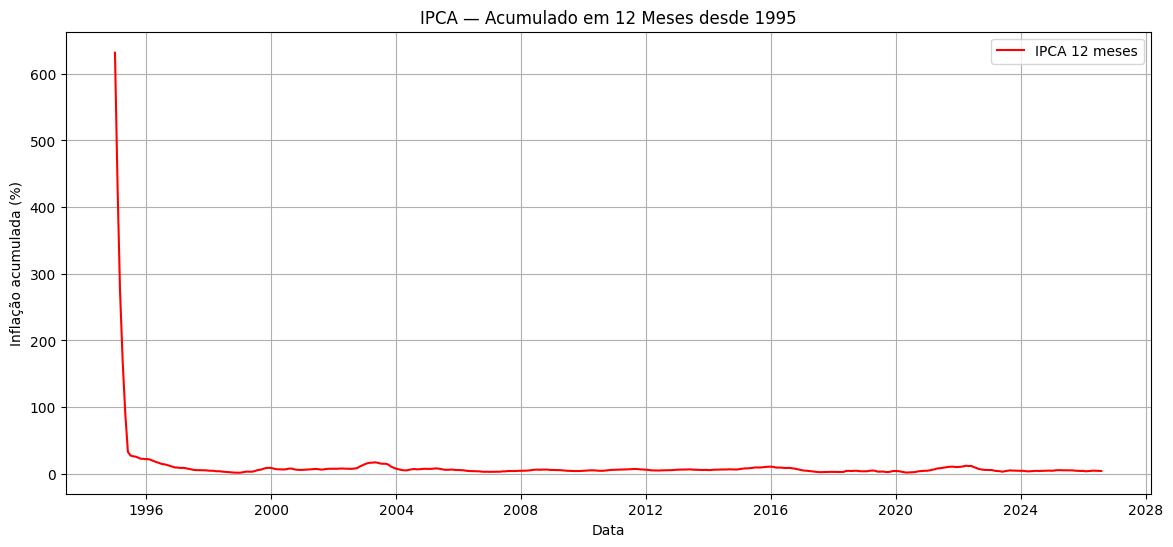

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    ipca_pos_1995["date"],
    ipca_pos_1995["acumulado12m"],
    color="red",
    label="IPCA 12 meses",
)

plt.title("IPCA — Acumulado em 12 Meses desde 1995")
plt.xlabel("Data")
plt.ylabel("Inflação acumulada (%)")
plt.grid(True)
plt.legend()

plt.show()

### 15. Evolução recente do acumulado em 12 meses

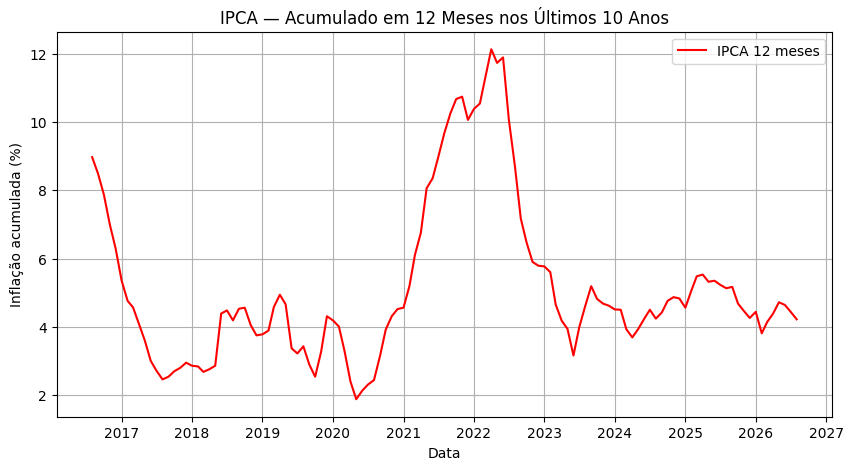

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    ipca_10a["date"],
    ipca_10a["acumulado12m"],
    color="red",
    label="IPCA 12 meses",
)

plt.title("IPCA — Acumulado em 12 Meses nos Últimos 10 Anos")
plt.xlabel("Data")
plt.ylabel("Inflação acumulada (%)")
plt.grid(True)
plt.legend()

plt.show()

---

## PARTE III — ACELERAÇÃO E DESACELERAÇÃO



### 16. Variação da inflação mensal

Calculamos:

$$
\Delta IPCA_t = IPCA_t - IPCA_{t-1}
$$

- Valores positivos $\to\qquad$ indicam que a inflação mensal foi maior que no mês
anterior.
- Valores negativos $\to\qquad$ indicam redução da inflação mensal em relação ao mês
anterior.

In [17]:
ipca["delta_indice"] = (ipca["indice"].diff())

ipca[
    [
        "date",
        "indice",
        "delta_indice",
    ]
].tail(8)

,date,indice,delta_indice
553,2026-01-01,0.3300,0.0000
554,2026-02-01,0.7000,0.3700
555,2026-03-01,0.8800,0.1800
556,2026-04-01,0.6700,-0.2100
557,2026-05-01,0.5800,-0.0900
558,2026-06-01,0.1600,-0.4200
559,2026-07-01,0.0700,-0.0900
560,2026-08-01,-0.3200,-0.3900


### 17. Variação da inflação acumulada em 12 meses

A diferença mensal do acumulado em 12 meses permite observar se essa
medida está acelerando ou desacelerando.

In [18]:
ipca["delta_12m"] = (ipca["acumulado12m"].diff())

ipca[
    [
        "date",
        "acumulado12m",
        "delta_12m",
    ]
].tail(8)

,date,acumulado12m,delta_12m
553,2026-01-01,4.4400,0.1800
554,2026-02-01,3.8100,-0.6300
555,2026-03-01,4.1400,0.3300
556,2026-04-01,4.3900,0.2500
557,2026-05-01,4.7200,0.3300
558,2026-06-01,4.6400,-0.0800
559,2026-07-01,4.4400,-0.2000
560,2026-08-01,4.2200,-0.2200


### 18. Classificação simples da dinâmica de 12 meses

Criamos uma classificação descritiva:

$\Delta_{12m} > 0 \to\qquad$ aceleração  
$\Delta_{12m} < 0 \to\qquad$ desaceleração  
$\Delta_{12m} = 0 \to\qquad$ estabilidade  

Essa classificação não representa previsão ou causalidade.

In [19]:
ipca["dinamica_12m"] = np.select(
    [
        ipca["delta_12m"] > 0,
        ipca["delta_12m"] < 0,
    ],
    [
        "aceleracao",
        "desaceleracao",
    ],
    default="estabilidade",
)

ipca[
    [
        "date",
        "acumulado12m",
        "delta_12m",
        "dinamica_12m",
    ]
].tail(12)

,date,acumulado12m,delta_12m,dinamica_12m
549,2025-09-01,5.1700,0.0400,aceleracao
550,2025-10-01,4.6800,-0.4900,desaceleracao
551,2025-11-01,4.4600,-0.2200,desaceleracao
552,2025-12-01,4.2600,-0.2000,desaceleracao
553,2026-01-01,4.4400,0.1800,aceleracao
554,2026-02-01,3.8100,-0.6300,desaceleracao
555,2026-03-01,4.1400,0.3300,aceleracao
556,2026-04-01,4.3900,0.2500,aceleracao
557,2026-05-01,4.7200,0.3300,aceleracao
558,2026-06-01,4.6400,-0.0800,desaceleracao


### 19. Frequência da dinâmica de 12 meses

In [20]:
ipca["dinamica_12m"].value_counts()

dinamica_12m
aceleracao       293
desaceleracao    254
estabilidade      14
Name: count, dtype: int64

### 20. Evolução recente da aceleração/desaceleração

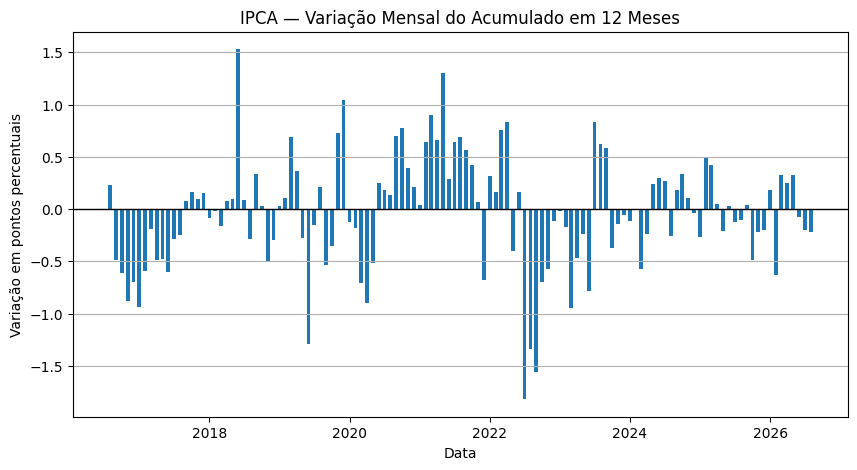

In [21]:
ipca_dinamica_recente = (ipca[ipca["date"] >= data_inicio_10a].copy())

plt.figure(figsize=(10, 5))

plt.bar(
    ipca_dinamica_recente["date"],
    ipca_dinamica_recente["delta_12m"],
    width=20,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Variação Mensal do Acumulado em 12 Meses"
)
plt.xlabel("Data")
plt.ylabel("Variação em pontos percentuais")
plt.grid(True, axis="y")

plt.show()

---

## PARTE IV — DINÂMICA DE CURTO E MÉDIO PRAZO



### 21. Médias móveis da inflação mensal

Calculamos médias móveis simples da variação mensal:

$mm3  \to\qquad$ média dos últimos 3 meses  
$mm6  \to\qquad$ média dos últimos 6 meses  
$mm12 \to\qquad$ média dos últimos 12 meses

Essas medidas suavizam oscilações mensais e ajudam a visualizar a direção
recente da inflação.

Importante: $mm12\quad !=\quad$ acumulado12m

A média móvel de 12 meses é uma média aritmética das variações mensais.
O acumulado em 12 meses representa uma medida acumulada da inflação.

In [22]:
ipca["mm3"] = (ipca["indice"].rolling(3).mean())

ipca["mm6"] = (ipca["indice"].rolling(6).mean())

ipca["mm12"] = (ipca["indice"].rolling(12).mean())

### 22. Médias móveis no período recente

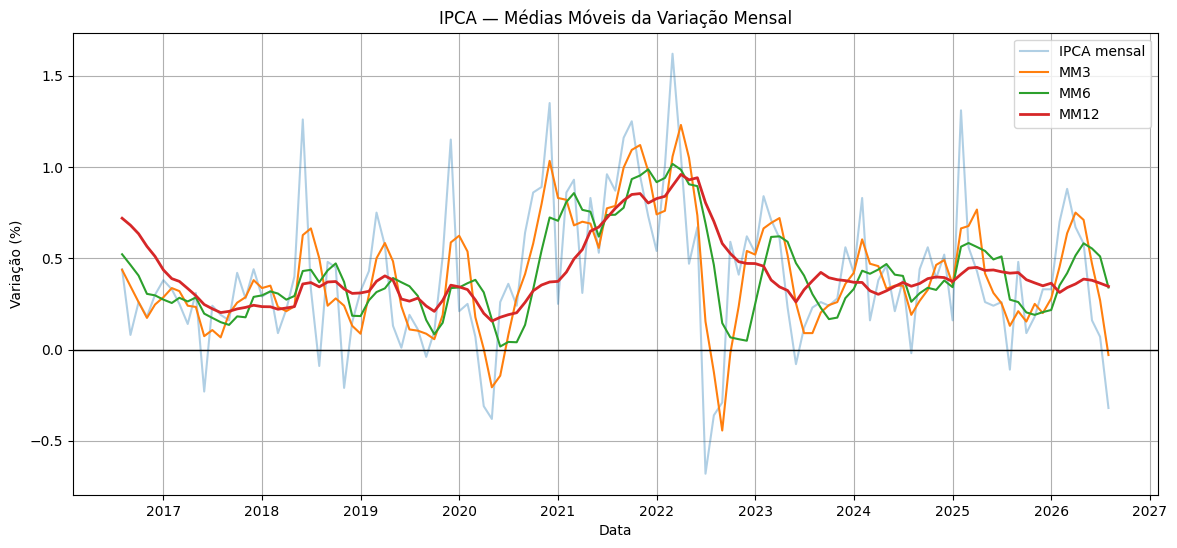

In [23]:
ipca_medias_recente = ipca[ipca["date"] >= data_inicio_10a].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    ipca_medias_recente["date"],
    ipca_medias_recente["indice"],
    alpha=0.35,
    label="IPCA mensal",
)

plt.plot(
    ipca_medias_recente["date"],
    ipca_medias_recente["mm3"],
    label="MM3",
)

plt.plot(
    ipca_medias_recente["date"],
    ipca_medias_recente["mm6"],
    label="MM6",
)

plt.plot(
    ipca_medias_recente["date"],
    ipca_medias_recente["mm12"],
    linewidth=2,
    label="MM12",
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title("IPCA — Médias Móveis da Variação Mensal")
plt.xlabel("Data")
plt.ylabel("Variação (%)")
plt.grid(True)
plt.legend()

plt.show()

### 23. Heatmap dos últimos 24 meses

O heatmap facilita a leitura de períodos recentes de:

- inflação mensal mais elevada;
- inflação mensal mais baixa;
- deflação.

Mantemos `date` como datetime no DataFrame principal e criamos apenas
um rótulo específico para visualização.

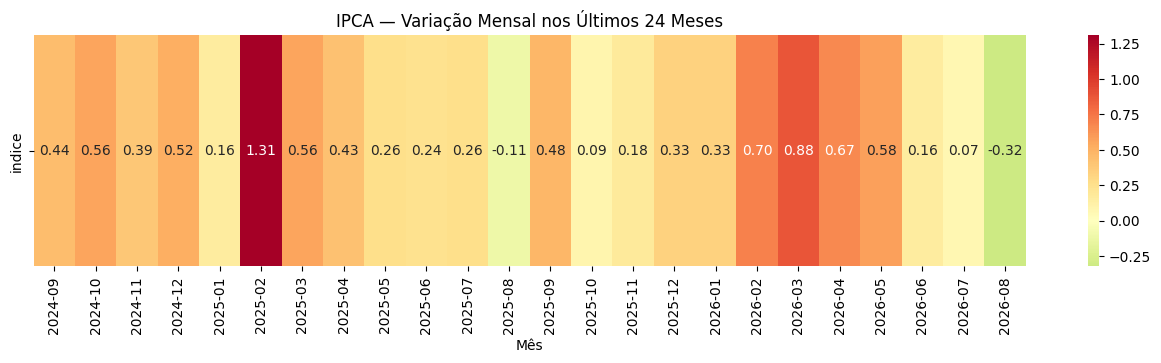

In [24]:
ipca_24m = (
    ipca[
        ["date", "indice"]
    ]
    .tail(24)
    .copy()
)

ipca_24m["periodo"] = (
    ipca_24m["date"]
    .dt.strftime("%Y-%m")
)

heatmap_data = (
    ipca_24m
    .set_index("periodo")[["indice"]]
    .T
)

plt.figure(figsize=(16, 3))

sns.heatmap(
    heatmap_data,
    cmap="RdYlGn_r",
    center=0,
    annot=True,
    fmt=".2f",
)

plt.title(
    "IPCA — Variação Mensal nos Últimos 24 Meses"
)
plt.xlabel("Mês")
plt.ylabel("")

plt.show()

---

## PARTE V — NÚMERO-ÍNDICE



### 24. Evolução do número-índice

Enquanto a variação mensal mede a mudança de preços em determinado mês,
o número-índice representa o nível acumulado da série.

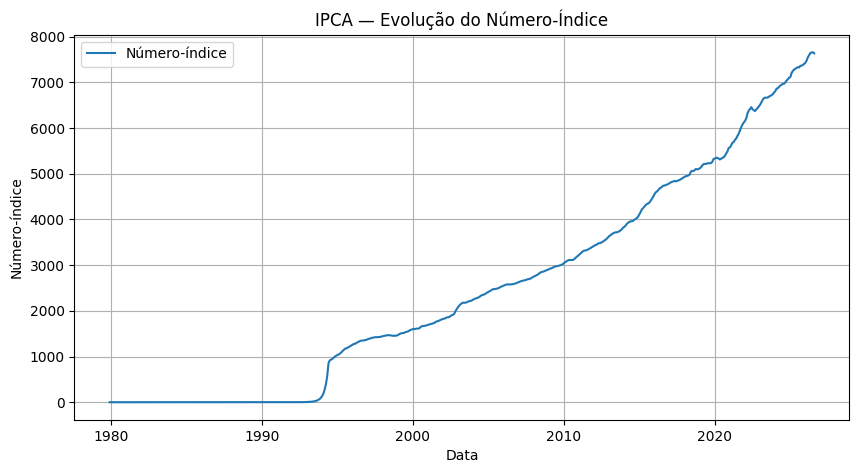

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    ipca["date"],
    ipca["nindice"],
    label="Número-índice",
)

plt.title("IPCA — Evolução do Número-Índice")
plt.xlabel("Data")
plt.ylabel("Número-índice")
plt.grid(True)
plt.legend()

plt.show()

### 25. Relação entre número-índice e variação mensal

Conceitualmente:

```text
número-índice
     |
     +--> nível da série de preços

variação mensal
     |
     +--> mudança percentual daquele nível
```

Essa distinção será importante quando definirmos o target de previsão.

Para forecasting da inflação, em geral estaremos interessados em prever
uma taxa de variação futura, e não simplesmente o nível nominal do
número-índice.

---

## PARTE VI — COMPARAÇÃO DA DINÂMICA RECENTE



### 26. Inflação mensal e acumulada em 12 meses

As duas medidas possuem escalas e interpretações diferentes.

Para evitar confusão visual, apresentamos as séries em painéis separados,
mas utilizando o mesmo eixo temporal.

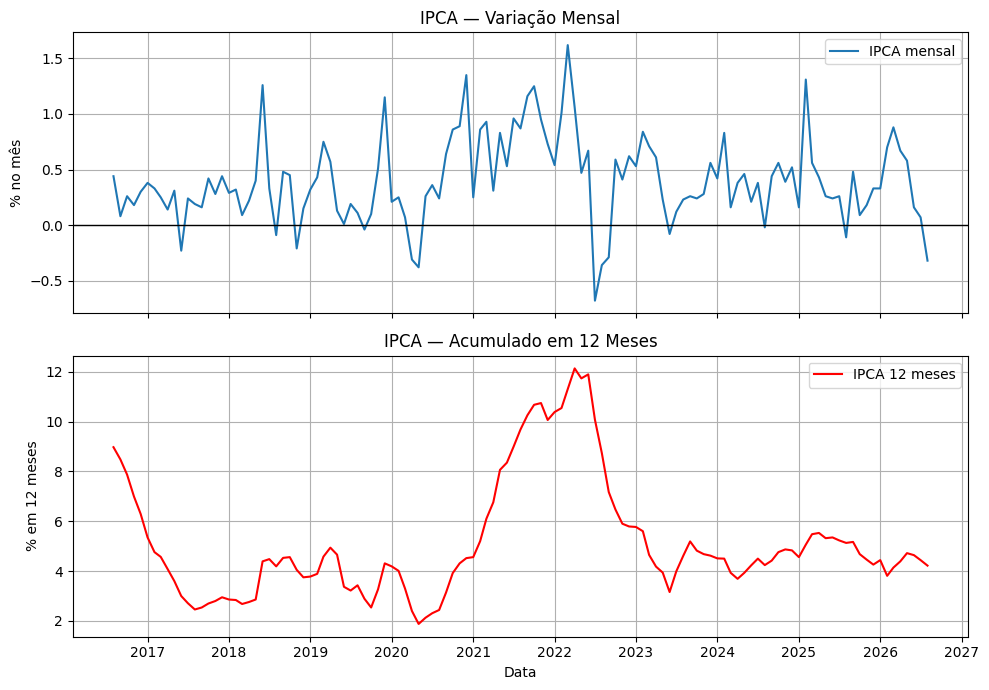

In [26]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 7),
    sharex=True,
)

axes[0].plot(
    ipca_10a["date"],
    ipca_10a["indice"],
    label="IPCA mensal",
)

axes[0].axhline(
    0,
    color="black",
    linewidth=1,
)

axes[0].set_title(
    "IPCA — Variação Mensal"
)
axes[0].set_ylabel("% no mês")
axes[0].grid(True)
axes[0].legend()


axes[1].plot(
    ipca_10a["date"],
    ipca_10a["acumulado12m"],
    color="red",
    label="IPCA 12 meses",
)

axes[1].set_title(
    "IPCA — Acumulado em 12 Meses"
)
axes[1].set_xlabel("Data")
axes[1].set_ylabel("% em 12 meses")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

---

## PARTE VII — PREPARAÇÃO PARA ANÁLISES POSTERIORES



### 27. Estrutura mensal

Diferentemente da SELIC, o IPCA geral já possui naturalmente frequência
mensal.

Portanto:

```text
IPCA
 |
 +--> uma observação por mês
```

Isso será a referência temporal para integrar posteriormente:

```text
IPCA
 +
SELIC Meta mensal
 +
SELIC Over mensal
 +
componentes do IPCA
```

A existência de um calendário mensal comum será fundamental para a futura
construção das features.

### 28. Dataset analítico preliminar

Criamos uma visão reduzida da série contendo algumas variáveis derivadas
exploradas neste notebook.

In [27]:
ipca_analitico = ipca[
    [
        "date",
        "indice",
        "nindice",
        "acumulado",
        "acumulado12m",
        "delta_indice",
        "delta_12m",
        "dinamica_12m",
        "mm3",
        "mm6",
        "mm12",
    ]
].copy()

ipca_analitico.tail(12)

,date,indice,nindice,acumulado,acumulado12m,delta_indice,delta_12m,dinamica_12m,mm3,mm6,mm12
549,2025-09-01,0.4800,7359.0600,3.6400,5.1700,0.5900,0.0400,aceleracao,0.2100,0.2600,0.4217
550,2025-10-01,0.0900,7365.6800,3.7300,4.6800,-0.3900,-0.4900,desaceleracao,0.1533,0.2033,0.3825
551,2025-11-01,0.1800,7378.9400,3.9200,4.4600,0.0900,-0.2200,desaceleracao,0.2500,0.1900,0.3650
552,2025-12-01,0.3300,7403.2900,4.2600,4.2600,0.1500,-0.2000,desaceleracao,0.2000,0.2050,0.3492
553,2026-01-01,0.3300,7427.7200,0.3300,4.4400,0.0000,0.1800,aceleracao,0.2800,0.2167,0.3633
554,2026-02-01,0.7000,7479.7100,1.0300,3.8100,0.3700,-0.6300,desaceleracao,0.4533,0.3517,0.3125
555,2026-03-01,0.8800,7545.5300,1.9200,4.1400,0.1800,0.3300,aceleracao,0.6367,0.4183,0.3392
556,2026-04-01,0.6700,7596.0900,2.6000,4.3900,-0.2100,0.2500,aceleracao,0.7500,0.5150,0.3592
557,2026-05-01,0.5800,7640.1500,3.2000,4.7200,-0.0900,0.3300,aceleracao,0.7100,0.5817,0.3858
558,2026-06-01,0.1600,7652.3700,3.3600,4.6400,-0.4200,-0.0800,desaceleracao,0.4700,0.5533,0.3792


#### Importante

`ipca_analitico` ainda NÃO representa o dataset final de machine learning.

Variáveis como:

```text
mm3
mm6
mm12
delta_indice
delta_12m
```

são transformações exploratórias.

Antes de utilizá-las em um modelo será necessário definir:

- qual será o target;
- qual será o horizonte de previsão;
- quais informações estavam disponíveis no momento da previsão;
- quais defasagens serão utilizadas;
- como será realizado o split temporal;
- como evitar leakage.

### 29. Target futuro de modelagem

Uma das decisões mais importantes da próxima fase será definir exatamente
o que queremos prever.

Algumas possibilidades:

#### IPCA do próximo mês $\to\qquad y_t = IPCA_{t+1}$

#### IPCA três meses à frente $\to\qquad y_t = IPCA_{t+3}$

#### Inflação acumulada futura $\to\qquad y_t = IPCA12M_{t+h}$

Cada definição gera um problema de machine learning diferente.

Portanto, ainda não deslocamos o target neste notebook.

### 30. Defasagens futuras

Posteriormente, poderemos construir features como:

$$X_t = [
IPCA_{t-1},
IPCA_{t-2},
IPCA_{t-3},
SELIC_{t-1},
SELIC_{t-2},
\ldots]
$$

Essa estrutura transforma a série temporal em um problema supervisionado.

Um cuidado será fundamental:

```text
informação disponível até t
         |
         v
       modelo
         |
         v
previsão de t+h
```

Nenhuma informação posterior a `t` poderá entrar nas features utilizadas
para produzir a previsão.

---

### 31. Próxima decomposição do IPCA

Até este ponto analisamos apenas:

```text
             IPCA geral
                 |
                 v
         comportamento agregado
```

Essa análise responde:

> Quanto a inflação variou?

Os próximos notebooks acrescentarão uma segunda pergunta:

> Quais componentes explicam essa variação?

Utilizaremos:

```text
IPCA geral
     |
     +--> grupos
            |
            +--> subgrupos
                    |
                    +--> itens
                            |
                            +--> subitens
```

Isso permitirá estudar:

- contribuição dos grupos;
- composição da inflação;
- disseminação dos aumentos de preços;
- mudanças na estrutura inflacionária;
- potenciais features para forecasting.

### 32. Conclusões

Este notebook estabeleceu a visão agregada da inflação brasileira utilizada
no projeto.



#### IPCA mensal

Representa a variação observada dos preços em cada mês e apresenta grande
diferença de comportamento entre períodos históricos.

#### IPCA acumulado em 12 meses

Oferece uma visão mais persistente da dinâmica inflacionária e permite
observar fases de aceleração e desaceleração.

#### Regimes históricos

O histórico completo inclui períodos com dinâmicas inflacionárias muito
distintas.

Isso será importante para a modelagem porque relações observadas em um
regime econômico podem não se manter em outro.

#### Dinâmica recente

Médias móveis e diferenças mensais ajudam a descrever o comportamento
recente, mas ainda não representam automaticamente features válidas para
forecasting.

#### Estrutura temporal

O IPCA possui frequência mensal e servirá como referência para alinhar
as demais variáveis macroeconômicas do projeto.

---



#### Evolução do projeto

```text
00.auditoria_dados
       |
       v
qualidade e integridade

01.selic
       |
       v
política monetária

02.ipca
       |
       v
inflação agregada

componentes do IPCA
       |
       v
decomposição da inflação

IPCA + SELIC
       |
       v
relações temporais

features
       |
       v
modelos estatísticos
       |
       v
machine learning
       |
       v
forecasting
```

O próximo passo é aprofundar a estrutura interna do IPCA antes de
integrar inflação e política monetária em um mesmo problema de modelagem.